# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Evina Fitriyani | 5054251013 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')

print('jumlah baris dan kolom:', df.shape)
df.info()
print(df.describe())

print('\nmissing value per kolom:')
print(df.isnull().sum())

# status_id selalu unik, jadi duplikat dicek tanpa status_id
print('\nbaris duplikat (dengan status_id):', df.duplicated().sum())
print('baris duplikat (tanpa status_id):', df.drop(columns='status_id').duplicated().sum())
print('kolom yang kosong semua:', df.columns[df.isnull().all()].tolist())

jumlah baris dan kolom: (7050, 16)
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int

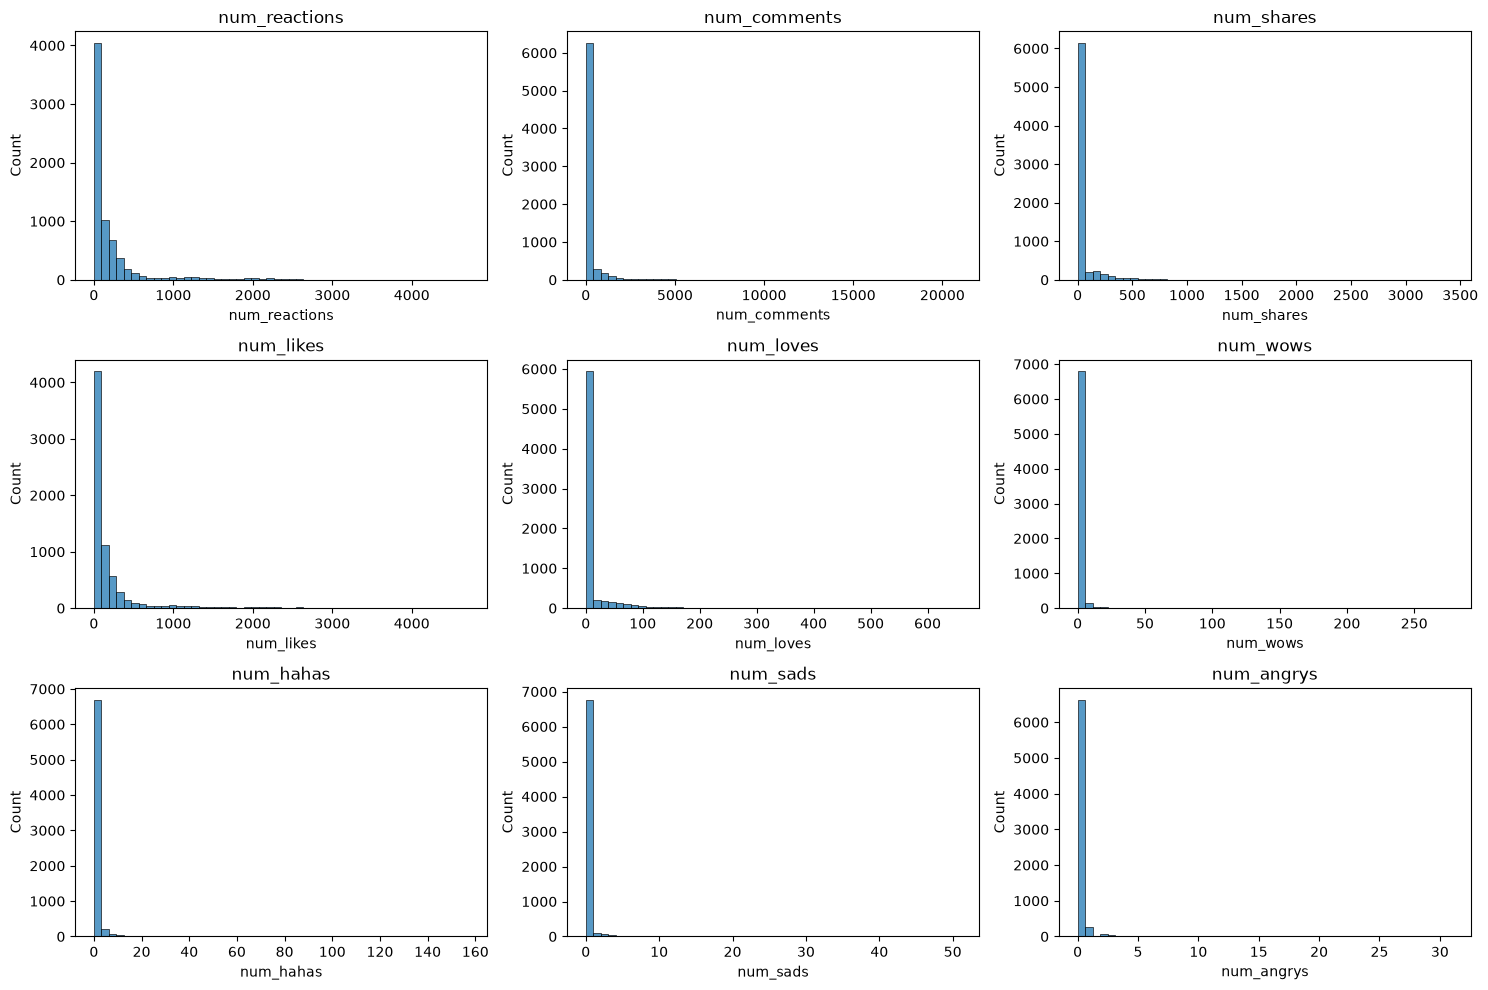

skewness:
num_reactions     3.738452
num_comments      9.028850
num_shares        7.099332
num_likes         3.919128
num_loves         6.004845
num_wows         18.246813
num_hahas        20.305741
num_sads         17.578868
num_angrys       19.507129
dtype: float64

proporsi nilai nol:
num_reactions    0.017163
num_comments     0.300567
num_shares       0.554752
num_likes        0.017872
num_loves        0.600000
num_wows         0.752908
num_hahas        0.839149
num_sads         0.913901
num_angrys       0.940000
dtype: float64


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
kolom_hitung = ['num_reactions', 'num_comments', 'num_shares', 'num_likes',
                'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

fig, axes = plt.subplots(3, 3, figsize=(15,10))
axes = axes.flatten()

for i, col in enumerate(kolom_hitung):
    sns.histplot(df[col], bins=50, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

print('skewness:')
print(df[kolom_hitung].skew())
print('\nproporsi nilai nol:')
print((df[kolom_hitung] == 0).mean())

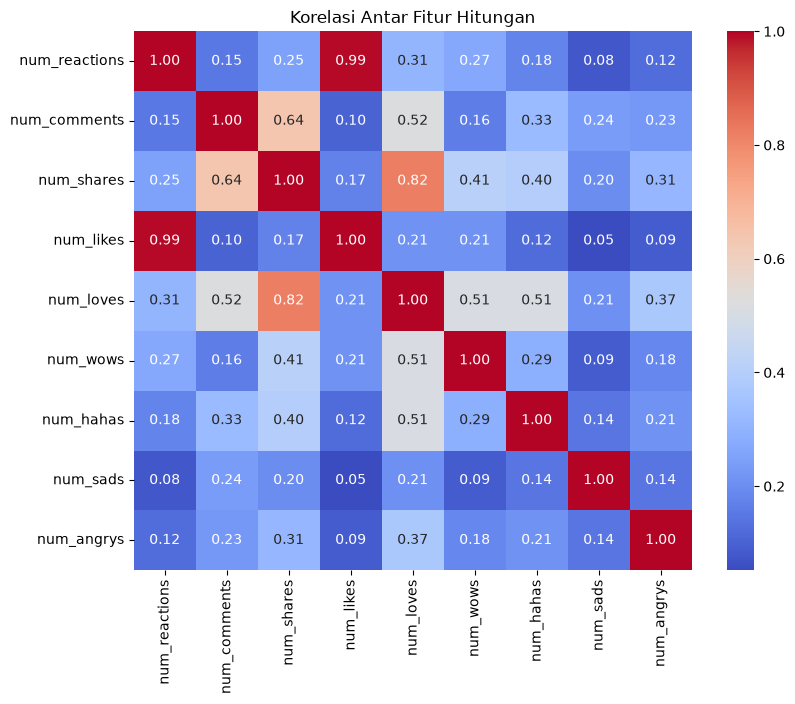

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9,7))
sns.heatmap(df[kolom_hitung].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Antar Fitur Hitungan')
plt.show()

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
df['tahun'] = df['status_published'].dt.year

# posting punya reaksi emoji kalau salah satu dari loves/wows/hahas/sads/angrys > 0
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['ada_emoji'] = df[emoji_cols].sum(axis=1) > 0

per_tahun = df.groupby('tahun').agg(jumlah_posting=('status_id', 'count'),
                                    proporsi_emoji=('ada_emoji', 'mean'))
print(per_tahun)

       jumlah_posting  proporsi_emoji
tahun                                
2012              589        0.000000
2013              500        0.000000
2014              233        0.000000
2015              337        0.000000
2016              588        0.680272
2017             2253        0.541944
2018             2550        0.577647


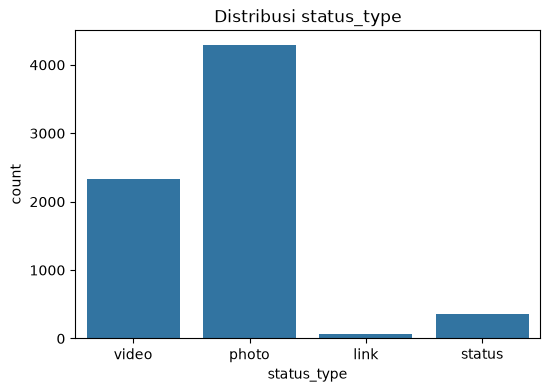

             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(6,4))
sns.countplot(x='status_type', data=df)
plt.title('Distribusi status_type')
plt.show()

print(df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median())

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [7]:
# EDA tambahan: komposisi status_type per tahun
print(pd.crosstab(df['tahun'], df['status_type']))

status_type  link  photo  status  video
tahun                                  
2012            0    589       0      0
2013            0    404       2     94
2014            1     25       0    207
2015           14    202      79     42
2016           14    403      51    120
2017           18   1269     122    844
2018           16   1396     111   1027


# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df = df.dropna(axis=1, how='all')
print('shape setelah hapus kolom kosong:', df.shape)

# duplikat dicek tanpa status_id
dup = df.drop(columns='status_id').duplicated()
print('jumlah duplikat:', dup.sum())
df = df[~dup].reset_index(drop=True)
print('shape setelah hapus duplikat:', df.shape)

print('\nsisa missing value:', df.isnull().sum().sum())

# outlier: liat nilai max dibanding persentil 99
print(df[kolom_hitung].describe(percentiles=[0.5, 0.99]).T[['50%', '99%', 'max']])
# outlier nggak dibuang, dibiarin karena bakal diredam sama log1p di bawah

shape setelah hapus kolom kosong: (7050, 14)
jumlah duplikat: 54
shape setelah hapus duplikat: (6996, 14)

sisa missing value: 0
                50%      99%      max
num_reactions  58.0  2293.20   4710.0
num_comments    4.0  4342.55  20990.0
num_shares      0.0   607.55   3424.0
num_likes      57.0  2288.15   4710.0
num_loves       0.0   198.10    657.0
num_wows        0.0    14.05    278.0
num_hahas       0.0    12.00    157.0
num_sads        0.0     4.00     51.0
num_angrys      0.0     3.00     31.0


In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
status_type = df['status_type']
status_published = df['status_published']

df_fitur = df.drop(columns=['status_id', 'status_type', 'status_published', 'tahun', 'ada_emoji'])

# cek redundan: apa num_reactions = jumlah semua reaksi?
reaksi = ['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
print('num_reactions == jumlah reaksi:', (df_fitur['num_reactions'] == df_fitur[reaksi].sum(axis=1)).mean())

# cek proporsi nol tiap fitur
print((df_fitur == 0).mean())

# emoji yang jarang dipake digabung jadi satu
df_fitur['num_emoji'] = df_fitur[['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)

fitur_pilih = ['num_comments', 'num_shares', 'num_likes', 'num_emoji']
X = df_fitur[fitur_pilih]
X.head()

num_reactions == jumlah reaksi: 0.9987135506003431
num_reactions    0.016867
num_comments     0.302459
num_shares       0.558176
num_likes        0.017581
num_loves        0.603917
num_wows         0.756718
num_hahas        0.840337
num_sads         0.914523
num_angrys       0.939966
dtype: float64


,num_comments,num_shares,num_likes,num_emoji
0,512,262,432,97
1,0,0,150,0
2,236,57,204,23
3,0,0,111,0
4,0,0,204,9


Fitur yang dipilih: `num_comments`, `num_shares`, `num_likes`, dan `num_emoji`.

`num_reactions` dibuang karena isinya hampir selalu sama dengan penjumlahan num_likes + num_loves + num_wows + num_hahas + num_sads + num_angrys (cocok di 99,87% baris), dan korelasinya dengan num_likes 0,99. Kalau dipakai, informasi likes kehitung dua kali di perhitungan jarak. Reaksi emoji (loves, wows, hahas, sads, angrys) proporsi nolnya antara 60% sampai 94%, dan reaksi ini baru ada mulai 2016 (posting 2012-2015 semuanya nol). Karena terlalu sparse kalau dipakai satu-satu, kelimanya dijumlahkan jadi `num_emoji`. `num_likes` tetap dipisah karena nol-nya cuma sekitar 1,8%. status_id, status_type, dan status_published tidak jadi fitur, dua yang terakhir dipakai buat interpretasi cluster aja.

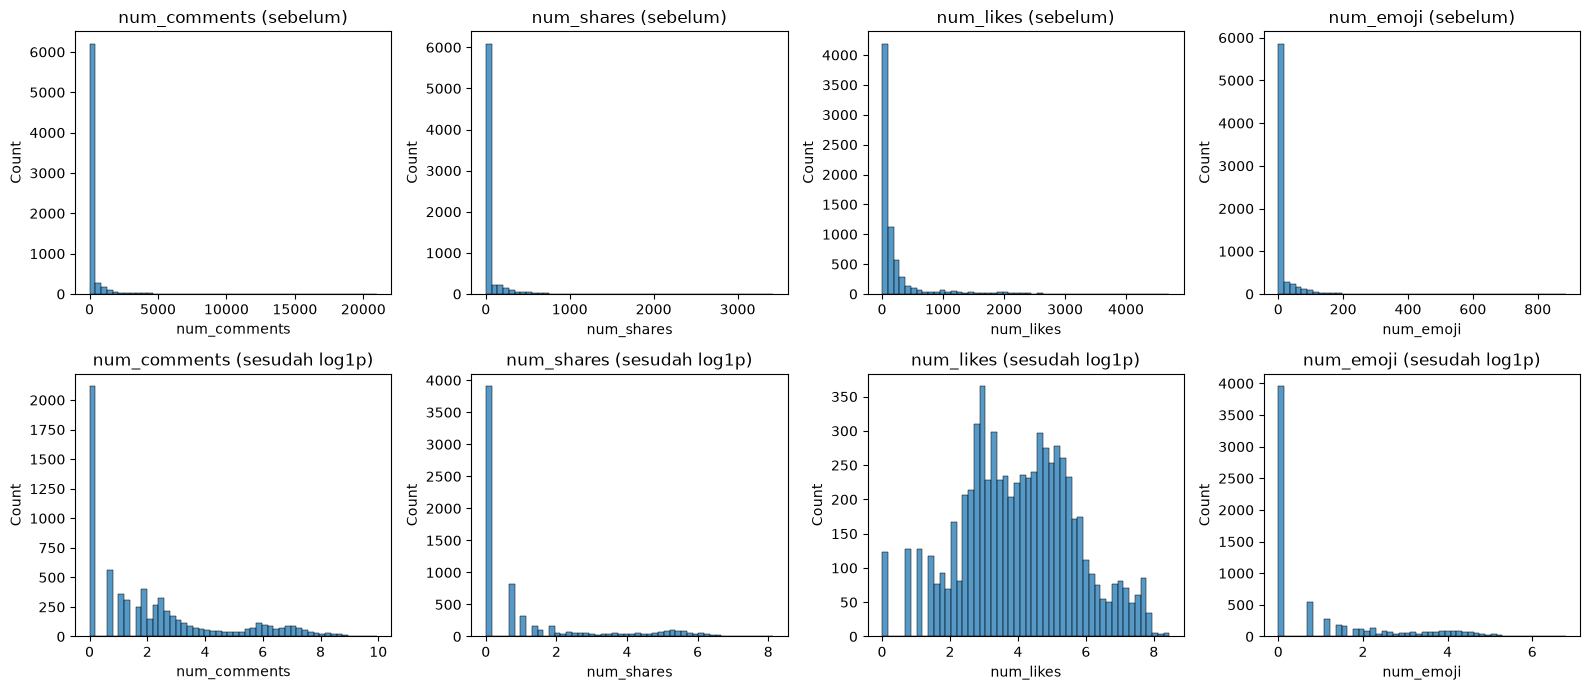

In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X)

fig, axes = plt.subplots(2, 4, figsize=(16,7))
for i, col in enumerate(fitur_pilih):
    sns.histplot(X[col], bins=50, ax=axes[0, i])
    axes[0, i].set_title(col + ' (sebelum)')
    sns.histplot(X_log[col], bins=50, ax=axes[1, i])
    axes[1, i].set_title(col + ' (sesudah log1p)')

plt.tight_layout()
plt.show()

In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_raw = X.copy()
X_raw_scaled = StandardScaler().fit_transform(X_raw)
X_log_scaled = StandardScaler().fit_transform(X_log)

print(X_raw.shape, X_raw_scaled.shape, X_log_scaled.shape)

(6996, 4) (6996, 4) (6996, 4)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
km_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_log_scaled)

In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
hasil_31 = {'X_raw': km_raw.labels_,
            'X_raw_scaled': km_raw_scaled.labels_,
            'X_log_scaled': km_log_scaled.labels_}

for nama, label in hasil_31.items():
    print(nama)
    print('  jumlah anggota:', np.bincount(label))
    print('  silhouette (di X_log_scaled):', round(silhouette_score(X_log_scaled, label), 4))

print('\nvarians tiap fitur pada data mentah:')
print(X_raw.var())

X_raw
  jumlah anggota: [6392  137  467]
  silhouette (di X_log_scaled): 0.2731
X_raw_scaled
  jumlah anggota: [ 373 6277  346]
  silhouette (di X_log_scaled): 0.2533
X_log_scaled
  jumlah anggota: [1131 2258 3607]
  silhouette (di X_log_scaled): 0.4638

varians tiap fitur pada data mentah:
num_comments    797310.065490
num_shares       17443.167343
num_likes       193268.441395
num_emoji         2299.572319
dtype: float64


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = range(2, 11)
inertia = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_log_scaled)
    inertia.append(km.inertia_)
    print('k =', k, '| inertia =', round(km.inertia_, 2))

k = 2 | inertia = 11586.9
k = 3 | inertia = 6779.84
k = 4 | inertia = 5678.25
k = 5 | inertia = 4739.96
k = 6 | inertia = 4220.28
k = 7 | inertia = 3772.1
k = 8 | inertia = 3418.57
k = 9 | inertia = 3116.43
k = 10 | inertia = 2899.05


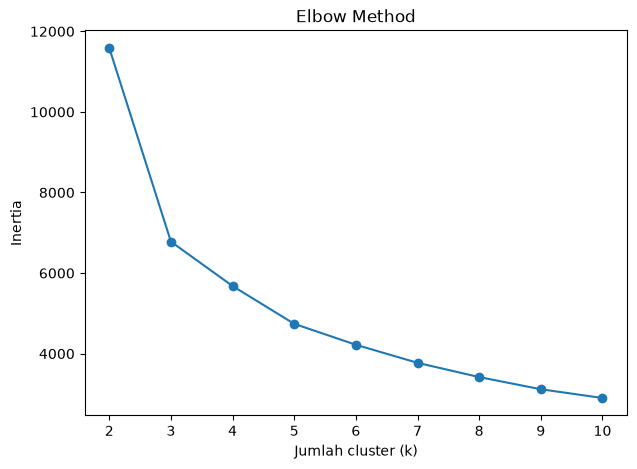

elbow menurut kneed: 4


In [18]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(7,5))
plt.plot(list(k_range), inertia, marker='o')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

# opsional, butuh pip install kneed
from kneed import KneeLocator
kl = KneeLocator(list(k_range), inertia, curve='convex', direction='decreasing')
print('elbow menurut kneed:', kl.elbow)

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [19]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_log_scaled)
    sil = silhouette_score(X_log_scaled, km.labels_)
    sil_scores.append(sil)
    print('k =', k, '| silhouette =', round(sil, 4))

k = 2 | silhouette = 0.5899
k = 3 | silhouette = 0.4638
k = 4 | silhouette = 0.3372
k = 5 | silhouette = 0.3586
k = 6 | silhouette = 0.3469
k = 7 | silhouette = 0.3367
k = 8 | silhouette = 0.3154
k = 9 | silhouette = 0.3293
k = 10 | silhouette = 0.316


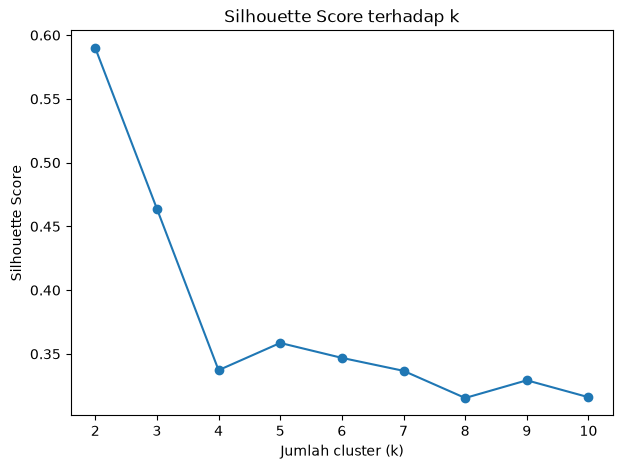

k terbaik menurut silhouette: 2


In [20]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(7,5))
plt.plot(list(k_range), sil_scores, marker='o')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score terhadap k')
plt.show()

print('k terbaik menurut silhouette:', list(k_range)[np.argmax(sil_scores)])

**Pilihan k untuk K-Means:** (isi nilai k yang kalian pilih beserta alasan singkatnya)

## 3.4 Model K-Means Final

In [21]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
k_final = 3  # ganti sesuai k yang kamu pilih dari 3.2 dan 3.3

kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
label_kmeans = kmeans_final.fit_predict(X_log_scaled)

print(np.bincount(label_kmeans))

[1131 2258 3607]


In [22]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
profil_km = X.copy()
profil_km['cluster'] = label_kmeans

print('median:')
print(profil_km.groupby('cluster').median())
print('\nrata-rata:')
print(profil_km.groupby('cluster').mean())
print('\njumlah anggota:')
print(profil_km['cluster'].value_counts().sort_index())

median:
         num_comments  num_shares  num_likes  num_emoji
cluster                                                
0               722.0       178.0      170.0       57.0
1                11.0         1.0      206.0        2.0
2                 0.0         0.0       18.0        0.0

rata-rata:
         num_comments  num_shares   num_likes  num_emoji
cluster                                                 
0         1335.369584  238.036251  304.495137  83.251105
1           26.888397    4.685120  462.733835   4.569531
2            2.113113    0.546715   22.228999   0.228999

jumlah anggota:
cluster
0    1131
1    2258
2    3607
Name: count, dtype: int64


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [23]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')

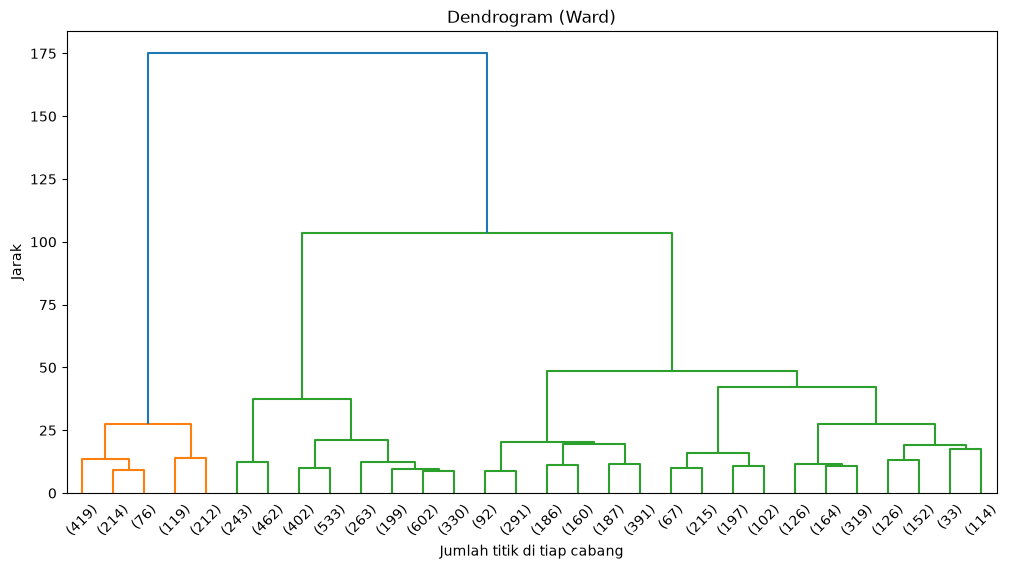

In [24]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12,6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward)')
plt.xlabel('Jumlah titik di tiap cabang')
plt.ylabel('Jarak')
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [25]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
metode_list = ['ward', 'complete', 'average', 'single']
label_linkage = {}

for metode in metode_list:
    hc = AgglomerativeClustering(n_clusters=k_final, linkage=metode)
    label_linkage[metode] = hc.fit_predict(X_log_scaled)

In [26]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
baris = []
for metode in metode_list:
    label = label_linkage[metode]
    baris.append({'Linkage': metode,
                  'Silhouette': silhouette_score(X_log_scaled, label),
                  'Jumlah anggota tiap cluster': np.bincount(label).tolist()})

tabel_linkage = pd.DataFrame(baris)
tabel_linkage

,Linkage,Silhouette,Jumlah anggota tiap cluster
0,ward,0.420118,"[2922, 1040, 3034]"
1,complete,0.116318,"[5775, 460, 761]"
2,average,0.506871,"[1197, 5764, 35]"
3,single,0.313948,"[6994, 1, 1]"


**Pilihan linkage untuk Hierarchical Clustering:** (isi linkage yang kalian pilih beserta alasan singkatnya)

## 4.3 Model Hierarchical Clustering Final

In [27]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
linkage_terbaik = 'ward'  # ganti sesuai hasil tabel di 4.2

hc_final = AgglomerativeClustering(n_clusters=k_final, linkage=linkage_terbaik)
label_hc = hc_final.fit_predict(X_log_scaled)

print(np.bincount(label_hc))

[2922 1040 3034]


In [28]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_hc = X.copy()
profil_hc['cluster'] = label_hc

print('median:')
print(profil_hc.groupby('cluster').median())
print('\nrata-rata:')
print(profil_hc.groupby('cluster').mean())
print('\njumlah anggota:')
print(profil_hc['cluster'].value_counts().sort_index())

median:
         num_comments  num_shares  num_likes  num_emoji
cluster                                                
0                 9.0         1.0      150.0        1.0
1               815.5       193.5      168.0       60.5
2                 0.0         0.0       14.0        0.0

rata-rata:
         num_comments  num_shares   num_likes  num_emoji
cluster                                                 
0           29.402806    5.272758  386.753251   4.477070
1         1430.190385  255.400962  277.532692  88.238462
2            1.755438    0.245880   16.707317   0.148649

jumlah anggota:
cluster
0    2922
1    1040
2    3034
Name: count, dtype: int64


# 5. Evaluasi Model

In [29]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
evaluasi = pd.DataFrame({
    'Model': ['K-Means', 'Hierarchical'],
    'Silhouette': [silhouette_score(X_log_scaled, label_kmeans), silhouette_score(X_log_scaled, label_hc)],
    'Davies-Bouldin': [davies_bouldin_score(X_log_scaled, label_kmeans), davies_bouldin_score(X_log_scaled, label_hc)],
    'Calinski-Harabasz': [calinski_harabasz_score(X_log_scaled, label_kmeans), calinski_harabasz_score(X_log_scaled, label_hc)]
})

evaluasi

,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.463799,0.830169,10935.461172
1,Hierarchical,0.420118,0.832856,9959.188214


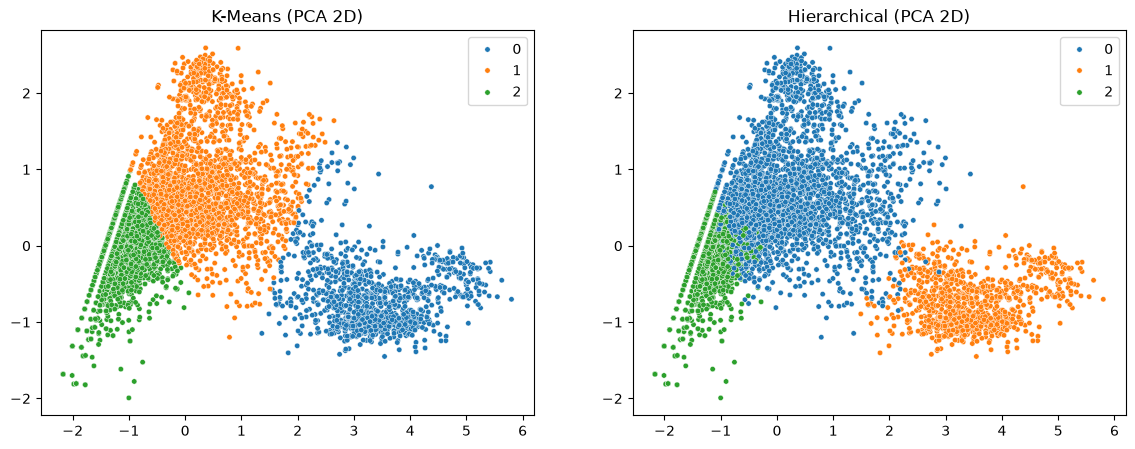

varians dijelaskan PC1 dan PC2: [75.8686466  15.95280647]
total: 91.82145306943188


In [30]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=label_kmeans, palette='tab10', s=15, ax=axes[0])
axes[0].set_title('K-Means (PCA 2D)')
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=label_hc, palette='tab10', s=15, ax=axes[1])
axes[1].set_title('Hierarchical (PCA 2D)')
plt.show()

print('varians dijelaskan PC1 dan PC2:', pca.explained_variance_ratio_ * 100)
print('total:', pca.explained_variance_ratio_.sum() * 100)

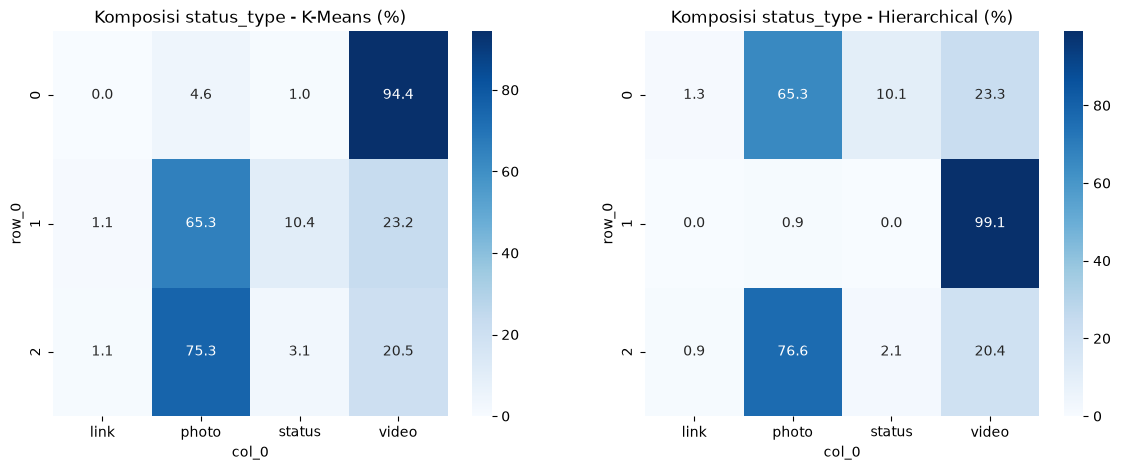

In [31]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
ct_km = pd.crosstab(label_kmeans, status_type.values, normalize='index') * 100
ct_hc = pd.crosstab(label_hc, status_type.values, normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.heatmap(ct_km, annot=True, fmt='.1f', cmap='Blues', ax=axes[0])
axes[0].set_title('Komposisi status_type - K-Means (%)')
sns.heatmap(ct_hc, annot=True, fmt='.1f', cmap='Blues', ax=axes[1])
axes[1].set_title('Komposisi status_type - Hierarchical (%)')
plt.show()

# 6. Analisis

**Pengaruh transformasi log dan feature scaling (3.1)**

Pada data mentah tanpa scaling, num_comments mendominasi karena variansnya paling besar (sekitar 797 ribu, dibanding num_likes 193 ribu, num_shares 17 ribu, dan num_emoji 2.300), jadi K-Means praktis cuma ngelompokin berdasarkan komentar. Hasilnya timpang [6392, 137, 467] dengan silhouette 0,273 (dihitung di ruang X_log_scaled). Kalau cuma di-scaling tanpa log, skalanya udah sama tapi outlier ekstrem masih ada (komentar maksimal 20.990 padahal mediannya 4), hasilnya satu cluster raksasa 6.277 titik dan dua cluster kecil (373 dan 346), silhouette malah turun jadi 0,253. Setelah log1p dan scaling, distribusi jadi lebih simetris dan jarak nggak lagi dikuasai outlier, hasilnya [1131, 2258, 3607] dengan silhouette 0,464. Keduanya penting di algoritma berbasis jarak: scaling nyamain pengaruh tiap fitur, sedangkan log1p meredam data yang sangat miring dan outlier supaya centroid nggak ketarik ke nilai ekstrem.

**Penanganan fitur redundan dan banyak nol**

num_reactions dibuang karena hampir selalu sama dengan jumlah semua reaksi (99,87% baris cocok) dan korelasinya dengan num_likes 0,99. Reaksi emoji nolnya banyak banget (loves 60%, wows 75%, hahas 84%, sads 91%, angrys 94%) dan baru ada sejak 2016, jadi kelimanya dijumlahkan jadi num_emoji supaya nggak sparse. Sisanya num_comments, num_shares, dan num_likes dipakai karena masing-masing punya makna yang beda. Sebelum itu, kolom Column1-4 yang kosong semua dihapus dan 54 baris duplikat dibuang (dicek tanpa status_id), sisa 6.996 baris.

**Jumlah cluster optimal**

Elbow Method nunjuk k=3 (inertia turun tajam sampai k=3 lalu melandai). Silhouette Score tertinggi di k=2 (0,590), disusul k=3 (0,464). Jadi hasilnya nggak sama persis. Aku pilih k=3 karena sikunya jelas di situ, dendrogram juga kebagi tiga, silhouette-nya masih cukup baik, dan k=2 terlalu kasar buat ngegambarin pola engagement.

**Perbandingan metode linkage**

Silhouette ward 0,420, complete 0,116, average 0,507, single 0,314. Average punya silhouette tertinggi tapi salah satu clusternya cuma 35 titik, jadi nilai tingginya nggak bikin hasilnya lebih berguna. Single linkage ngasih [6994, 1, 1]: dua cluster cuma berisi satu titik dan sisanya numpuk jadi satu. Ini karena single linkage ngukur jarak antar cluster dari dua titik terdekat, jadi titik-titik outlier nggak pernah ketarik ke cluster lain dan terbentuk rantai panjang buat data yang rapat. Complete juga timpang [5775, 460, 761] dengan silhouette paling rendah. Ward paling seimbang [2922, 1040, 3034], jadi ward yang paling baik buat data ini.

**K-Means vs Hierarchical Clustering**

K-Means unggul tipis di semua metrik: Silhouette 0,464 vs 0,420, Calinski-Harabasz 10.935 vs 9.959, sedangkan Davies-Bouldin hampir sama (0,830 vs 0,833). Dua komponen PCA menjelaskan 91,8% varians (PC1 75,9%, PC2 16,0%), jadi scatter-nya cukup mewakili datanya. Di scatter, kelompok di kanan bawah (engagement tinggi) kebentuk jelas di kedua metode, bedanya cuma batas antara dua cluster di sisi kiri yang agak bergeser. Ukuran clusternya juga mirip (K-Means 1131/2258/3607, Hierarchical 1040/2922/3034). Hasilnya mirip karena Ward ngegabungin cluster yang nambah variansi dalam cluster paling sedikit, tujuannya sama dengan K-Means yaitu minimalin jarak kuadrat ke pusat cluster.

**Karakteristik tiap cluster**

K-Means:
- Cluster 0, "Video Viral" (1.131 posting): median komentar 722, share 178, like 170, emoji 57. Komposisinya 94,4% video.
- Cluster 1, "Banyak Like, Sepi Obrolan" (2.258 posting): median like 206 tapi komentar cuma 11, share 1, emoji 2. Mayoritas foto (65,3%), video 23,2%, status 10,4%.
- Cluster 2, "Sepi Peminat" (3.607 posting): komentar 0, share 0, like 18, emoji 0. Mayoritas foto (75,3%), video 20,5%.

Hierarchical punya pola yang sama: cluster 1 (1.040 posting, 99,1% video) setara Video Viral, cluster 0 (2.922) setara Banyak Like Sepi Obrolan, dan cluster 2 (3.034) setara Sepi Peminat. Yang ngebedain cluster Video Viral dari yang lain justru komentar, share, dan emoji, bukan like (median like-nya malah lebih rendah dari cluster 1). Ini konsisten dengan median per status_type di EDA, video punya median komentar 39 dan share 12, sedangkan foto 2 dan 0.

**Kelebihan dan kekurangan**

K-Means cepat dan ringan buat data besar, tapi harus nentuin k di awal, hasilnya bisa beda tergantung inisialisasi, cenderung bikin cluster bulat dengan ukuran mirip, dan sensitif ke outlier serta skala fitur (kelihatan dari 3.1). Hierarchical nggak perlu nentuin k di awal karena bisa dilihat dari dendrogram, dan nunjukkin struktur penggabungan antar cluster, tapi butuh waktu dan memori yang naik kuadratik terhadap jumlah data, nggak bisa mindahin titik yang udah digabung, dan hasilnya sangat bergantung pada pilihan linkage (single dan complete jelek di data ini).

# 7. Kesimpulan dan Saran

Dari eksperimen ini, posting Facebook penjual di Thailand terbagi jadi tiga pola engagement: posting video dengan komentar, share, dan emoji tinggi, posting yang banyak di-like tapi sepi komentar dan share, dan posting dengan engagement yang rendah di semua sisi. Transformasi log1p dan scaling terbukti penting, karena silhouette naik dari 0,273 (data mentah) dan 0,253 (scaling saja) jadi 0,464 dan ukuran cluster jadi jauh lebih seimbang. Jumlah cluster k=3 dipilih dari elbow dan dendrogram, meskipun silhouette tertinggi ada di k=2. Pada Hierarchical Clustering, ward adalah linkage terbaik karena clusternya paling seimbang, sedangkan single dan average ngasih cluster yang isinya sangat sedikit titik. K-Means sedikit lebih baik dari Hierarchical (silhouette 0,464 vs 0,420), tapi selisihnya kecil dan cluster yang terbentuk hampir sama.

Saran untuk eksperimen selanjutnya:
- Clustering dipisah untuk periode sebelum dan sesudah 2016, karena reaksi emoji baru ada sejak 2016 sehingga num_emoji untuk posting lama pasti nol dan bisa ngaruh ke pembentukan cluster.
- Memanfaatkan fitur waktu seperti jam atau hari posting.
- Mencoba algoritma lain seperti DBSCAN atau Gaussian Mixture Model, yang bisa nangani cluster bentuk non-bulat dan outlier.
- Mencoba variasi n_init dan init pada K-Means, atau nggak menggabung emoji dan membandingkan hasilnya.